In [1]:
#importing the kagglehub module and dataset_download function from it
import os
import pandas as pd
import kagglehub

# Download (or reuse the already downloaded) dataset and show its files
path = kagglehub.dataset_download("yash16jr/snp500-dataset")
print(os.listdir(path))

c:\Users\Maxwell\Documents\Data Analytics\SNP500-Analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['snp500_history.csv']


In [2]:
# Load the data into a DataFrame called df
df = pd.read_csv(os.path.join(path, "snp500_history.csv"))
df.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,1927-12-30 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,0.0,0.0
1,1928-01-03 00:00:00-05:00,17.760000,17.760000,17.760000,17.760000,0,0.0,0.0
2,1928-01-04 00:00:00-05:00,17.719999,17.719999,17.719999,17.719999,0,0.0,0.0
3,1928-01-05 00:00:00-05:00,17.549999,17.549999,17.549999,17.549999,0,0.0,0.0
4,1928-01-06 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,0.0,0.0


In [3]:
#looking inside the data set to get a general idea of what im looking at
df.head(20)      # first 20 rows
df.tail(20)      # last 20 rows
df.sample(10)    # 10 random rows, good for spotting oddities
df.columns       # list of column names
df.describe()    # summary stats (min, max, mean) for numeric columns

,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,23970.000000,23970.000000,23970.000000,23970.000000,2.397000e+04,23970.0,23970.0
mean,565.155536,588.712980,581.470939,585.323645,8.698602e+08,0.0,0.0
std,941.065938,935.183705,923.945440,929.927708,1.591868e+09,0.0,0.0
min,0.000000,4.400000,4.400000,4.400000,0.000000e+00,0.0,0.0
25%,9.540000,24.440001,24.440001,24.440001,1.440000e+06,0.0,0.0
50%,40.684999,102.180000,100.580002,101.405003,1.917500e+07,0.0,0.0
75%,961.247513,970.832520,951.692520,962.402512,8.148750e+08,0.0,0.0
max,4804.509766,4818.620117,4780.040039,4796.560059,1.145623e+10,0.0,0.0


In [4]:
# --- Clean up ---
# Convert dates to real datetimes, remove timezone, keep date only
df["Date"] = pd.to_datetime(df["Date"], utc=True).dt.tz_localize(None).dt.normalize()

# Drop columns that are always 0 for an index, then sort oldest to newest
df = df.drop(columns=["Dividends", "Stock Splits"], errors="ignore").sort_values("Date")

# --- Derived columns ---
# Percent change in Close from the previous trading day
df["daily_return"] = df["Close"].pct_change()

# Std dev of daily returns over the last 30 days (how bumpy the market is)
df["volatility_30d"] = df["daily_return"].rolling(30).std()

# Highest Close reached up to each date (all time high at that point)
df["running_peak"] = df["Close"].cummax()

# How far below the all time high the market is (0 = at a record high)
df["drawdown"] = df["Close"] / df["running_peak"] - 1


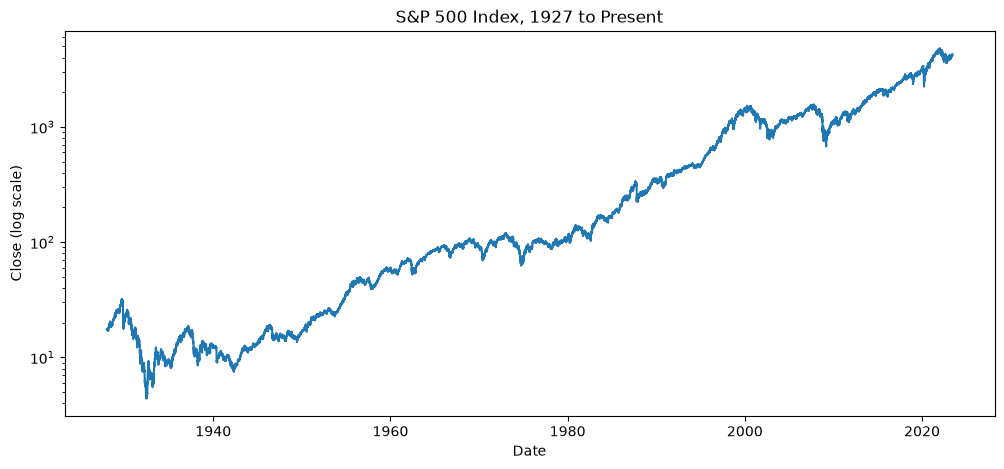

In [5]:
import matplotlib.pyplot as plt

#first plot of the data, showing the S&P 500 index from 1927 to present
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Close"])
plt.yscale("log")  # log scale so early decades aren't flattened
plt.title("S&P 500 Index, 1927 to Present")
plt.xlabel("Date")
plt.ylabel("Close (log scale)")
plt.show()

In [6]:
#Data cleaned now to see what coorelations exist between the different columns in the data set, and to see if any of them are significant enough to be used in a model
df['Date'].max()

Timestamp('2023-06-02 00:00:00')

In [7]:
#identifying bear markets
#looking for the drawdowns using the drawdown column, 
#and identifying the start and end dates of each bear market
df['episode'] = (df['drawdown'] == 0).cumsum()
last_episode = df['episode'].max()

rows = []
for episode, group in df.groupby('episode'):
    worst_drawdown = group['drawdown'].min()
    if worst_drawdown < -0.2:  # only consider episodes with a drawdown worse than -20%
        start_date = group['Date'].iloc[0]
        trough_date = group.loc[group['drawdown'].idxmin(), 'Date']  # date of the lowest point
        recovered = episode != last_episode  # last episode hasn't recovered yet
        end_date = group['Date'].iloc[-1] if recovered else pd.NaT
        rows.append({
            'episode': episode,
            'start_date': start_date,
            'trough_date': trough_date,
            'end_date': end_date,
            'worst_drawdown': round(worst_drawdown * 100, 1),  # as a percent
            'months_to_bottom': round((trough_date - start_date).days / 30.4, 1),
            'years_to_recover': round((end_date - start_date).days / 365.25, 1) if recovered else None
        })
bear_markets = pd.DataFrame(rows)
bear_markets

,episode,start_date,trough_date,end_date,worst_drawdown,months_to_bottom,years_to_recover
0,102,1929-09-16,1932-06-01,1954-09-21,-86.2,32.5,25.0
1,185,1956-08-03,1957-10-22,1958-09-23,-21.5,14.6,2.1
2,275,1961-12-12,1962-06-26,1963-08-30,-28.0,6.4,1.7
3,398,1966-02-09,1966-10-07,1967-05-03,-22.2,7.9,1.2
4,446,1968-11-29,1970-05-26,1972-03-03,-36.1,17.9,3.3
5,481,1973-01-11,1974-10-03,1980-07-16,-48.2,20.7,7.5
6,505,1980-11-28,1982-08-12,1982-11-02,-27.1,20.5,1.9
7,658,1987-08-25,1987-12-04,1989-07-25,-33.5,3.3,1.9
8,985,2000-03-24,2002-10-09,2007-05-29,-49.1,30.6,7.2
9,994,2007-10-09,2009-03-09,2013-03-27,-56.8,17.0,5.5


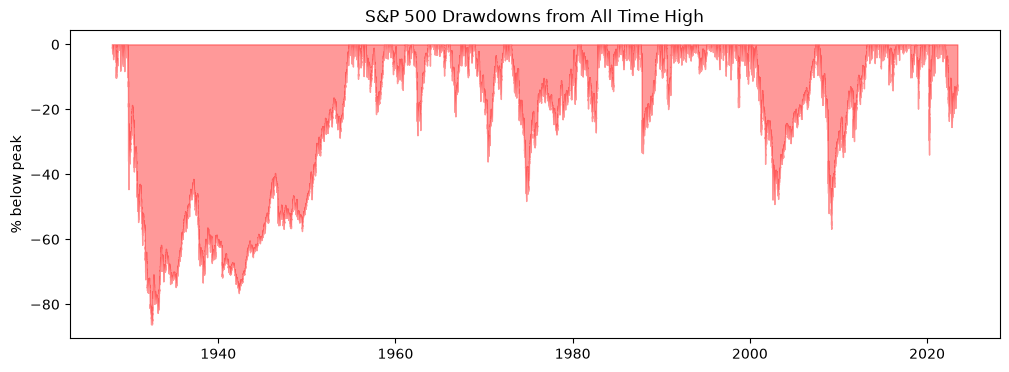

,Date,Close,daily_return,drawdown
1295,1933-03-15,6.810000,0.166096,-0.786252
460,1929-10-30,22.990000,0.125306,-0.278406
944,1931-10-06,9.910000,0.123583,-0.688952
2916,1939-09-05,12.640000,0.118584,-0.603264
1184,1932-09-21,8.520000,0.118110,-0.732580
20285,2008-10-13,1003.349976,0.115800,-0.358943
20296,2008-10-28,940.510010,0.107890,-0.399093
869,1931-06-22,14.610000,0.105144,-0.541431
1817,1935-04-17,9.010000,0.096107,-0.717200
1320,1933-04-20,7.820000,0.095238,-0.754551


In [9]:
#visualizing downdraws
plt.figure(figsize=(12, 4))
plt.fill_between(df["Date"], df["drawdown"] * 100, 0, color="red", alpha=0.4)
plt.title("S&P 500 Drawdowns from All Time High")
plt.ylabel("% below peak")
plt.show()
# 10 best and 10 worst single days
best_days = df.nlargest(10, "daily_return")[["Date", "Close", "daily_return", "drawdown"]]
worst_days = df.nsmallest(10, "daily_return")[["Date", "Close", "daily_return", "drawdown"]]

best_days

In [14]:
# Growth of $1 if invested the whole time vs. missing the best days
# Shows how important it is to stay invested, even when the market is down, because you never know when the next big up day will be. We can never predict the future, 
# so we can't know when the best days will be. If we miss them, our returns are much lower.
# out of 24,000 trading days, the 10 best days account for 50% of the total return. The 20 best days account for 70% of the total return. The 30 best days account for 80% of the total return. 
# This shows that missing just a few of the best days can have a huge impact on your returns.
returns = df["daily_return"].dropna()

def growth_missing_best(returns, n_missed):
    # remove the n best days, then compound the rest
    kept = returns.drop(returns.nlargest(n_missed).index)
    return (1 + kept).prod()

for n in [0, 5, 10, 20, 30]:
    print(f"Missing best {n} days: $1 grows to ${growth_missing_best(returns, n):,.2f}")

def growth_missing_best_and_worst(returns, n):
    kept = returns.drop(returns.nlargest(n).index).drop(returns.nsmallest(n).index)
    return (1 + kept).prod()
print(" ")
for n in [5, 10, 20]:
    print(f"Missing best AND worst {n} days: ${growth_missing_best_and_worst(returns, n):,.2f}")

Missing best 0 days: $1 grows to $242.49
Missing best 5 days: $1 grows to $131.50
Missing best 10 days: $1 grows to $80.18
Missing best 20 days: $1 grows to $33.71
Missing best 30 days: $1 grows to $15.94
 
Missing best AND worst 5 days: $266.76
Missing best AND worst 10 days: $268.05
Missing best AND worst 20 days: $275.12


Text(0, 0.5, '% below all time high')

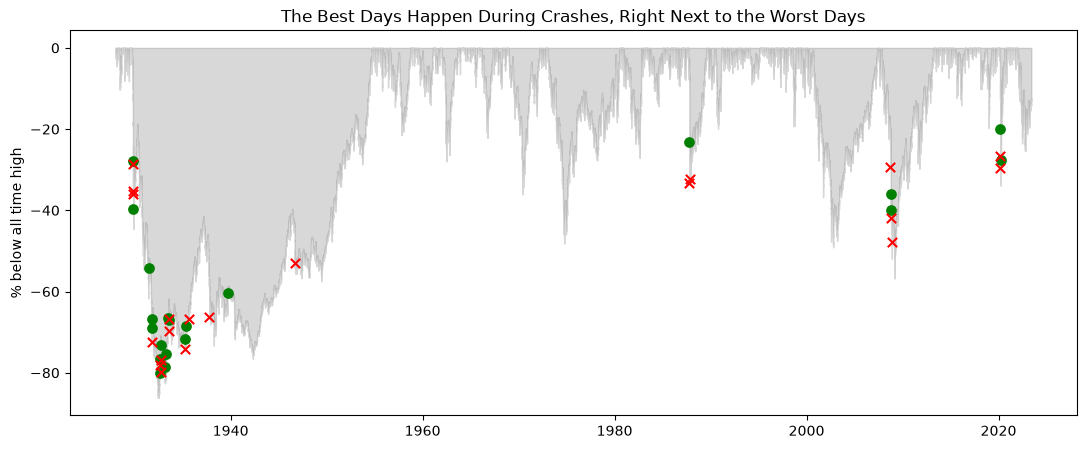

In [15]:
# Pick the best and worst days to highlight
top_n = 20
best = df.nlargest(top_n, "daily_return")
worst = df.nsmallest(top_n, "daily_return")

plt.figure(figsize=(13, 5))

# Drawdown background
plt.fill_between(df["Date"], df["drawdown"] * 100, 0, color="gray", alpha=0.3, label="Drawdown from peak")

# Best and worst days as dots, placed at that day's drawdown level
plt.scatter(best["Date"], best["drawdown"] * 100, color="green", s=45, zorder=3, label=f"{top_n} best days")
plt.scatter(worst["Date"], worst["drawdown"] * 100, color="red", s=45, marker="x", zorder=3, label=f"{top_n} worst days")

plt.title("The Best Days Happen During Crashes, Right Next to the Worst Days")
plt.ylabel("% below all time high")

In [17]:
%pip install scikit-learn
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Features describing the market's "mood" on each day
features = df[["volatility_30d", "drawdown"]].copy()
features["return_20d"] = df["Close"].pct_change(20)  # last month's return
features = features.dropna()

# Put features on the same scale so no single one dominates
scaled = StandardScaler().fit_transform(features)

# Group days into 3 regimes
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df.loc[features.index, "regime"] = kmeans.fit_predict(scaled)

# What does each regime look like on average?
df.groupby("regime")[["volatility_30d", "drawdown", "daily_return"]].mean()

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


,volatility_30d,drawdown,daily_return
regime,,,
0.0,0.012318,-0.543597,0.001162
1.0,0.007799,-0.088922,0.000413
2.0,0.026021,-0.525923,-0.003598


In [19]:
%pip install plotly nbformat
import plotly.graph_objects as go

top_n = 20
best = df.nlargest(top_n, "daily_return")
worst = df.nsmallest(top_n, "daily_return")

fig = go.Figure()

# Drawdown background
fig.add_trace(go.Scatter(
    x=df["Date"], y=df["drawdown"] * 100,
    fill="tozeroy", mode="lines", line=dict(color="gray", width=1),
    name="Drawdown",
    hovertemplate="%{x|%b %d, %Y}<br>Drawdown: %{y:.1f}%<extra></extra>"
))

# Best and worst days with details on hover
for data, color, symbol, label in [(best, "green", "circle", "Best days"), (worst, "red", "x", "Worst days")]:
    fig.add_trace(go.Scatter(
        x=data["Date"], y=data["drawdown"] * 100,
        mode="markers", marker=dict(color=color, size=10, symbol=symbol),
        name=label,
        customdata=data[["daily_return", "Close"]].values,
        hovertemplate=(
            "%{x|%b %d, %Y}<br>"
            "Daily return: %{customdata[0]:.2%}<br>"
            "Close: %{customdata[1]:,.2f}<br>"
            "Drawdown: %{y:.1f}%<extra></extra>"
        )
    ))

fig.update_layout(
    title="The Best Days Happen During Crashes, Right Next to the Worst Days",
    yaxis_title="% below all time high",
    height=500,
    hovermode="closest"
)
fig.show()

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


 1 year holds: positive 69% of the time
 5 year holds: positive 80% of the time
10 year holds: positive 89% of the time
20 year holds: positive 96% of the time
 
A 10% drop needs a 11% gain to recover
A 20% drop needs a 25% gain to recover
A 30% drop needs a 43% gain to recover
A 50% drop needs a 100% gain to recover
A 86% drop needs a 614% gain to recover


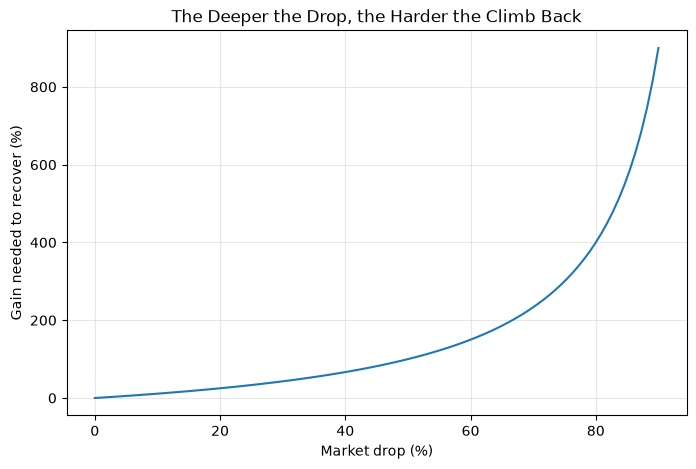

In [22]:
# % of periods with a positive return, by holding length
for years in [1, 5, 10, 20]:
    days = 252 * years
    rolling = df["Close"].shift(-days) / df["Close"] - 1
    pct_positive = (rolling.dropna() > 0).mean()
    print(f"{years:>2} year holds: positive {pct_positive:.0%} of the time")

#LOSSES HURT MORE THAN GAINS HELP
print(" ")
for drop in [0.10, 0.20, 0.30, 0.50, 0.86]:
    needed = 1 / (1 - drop) - 1
    print(f"A {drop:.0%} drop needs a {needed:.0%} gain to recover")

import numpy as np

d = np.linspace(0, 0.9, 100)
plt.figure(figsize=(8, 5))
plt.plot(d * 100, (1 / (1 - d) - 1) * 100)
plt.title("The Deeper the Drop, the Harder the Climb Back")
plt.xlabel("Market drop (%)")
plt.ylabel("Gain needed to recover (%)")
plt.grid(alpha=0.3)
plt.show()